# VAR estructurales (1): identificación recursiva y las tres lecturas

La sesión 2 cerró con una frase que ahora es el punto de partida: para **pronosticar**, cualquier
matriz $S$ con $SS' = \Sigma$ sirve igual. Para preguntas **estructurales**, no: de qué $S$ se
elija depende si la política monetaria contrae el producto o lo expande.

Este notebook cubre el problema de identificación, la identificación recursiva de Cholesky y las
tres lecturas de un VAR estructural.

**El sistema.** Economía pequeña y abierta, Perú trimestral, 2002Q1 a 2019Q4 (metas de inflación,
antes de la pandemia):

$$\mathbf{y}_t = (tot_t,\ y_t,\ \pi_t,\ i_t)'$$

términos de intercambio y PBI en variación interanual, inflación interanual y tasa interbancaria en
niveles. El orden va de lo más exógeno a lo que reacciona más rápido, y esa es ya la primera
decisión de identificación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from MacroPy import BayesianVAR, set_style
import sys; sys.path.append("..")          # course_data.py vive en la raíz del repositorio
import course_data as cd

set_style()

levels = cd.load()                          # copia congelada de la base del curso
Y = cd.small_open_economy(levels)                 # (tot, y, pi, i), 2002Q1-2019Q4
n, p = Y.shape[1], 2

print("base del curso, descargada el", cd.vintage())
print(f"muestra: {cd.quarter(Y.index[0])} a {cd.quarter(Y.index[-1])}, {len(Y)} trimestres")
Y.describe().round(2)

base del curso, descargada el 2026-10-03
muestra: 2002Q1 a 2019Q4, 72 trimestres


,tot,y,pi,i
count,72.00,72.00,72.00,72.00
mean,4.06,5.12,2.68,3.66
std,11.77,2.62,1.43,1.08
min,-23.62,-0.73,-1.01,1.15
25%,-3.54,3.13,1.86,2.89
50%,3.29,5.10,2.73,3.78
75%,8.70,6.49,3.48,4.25
max,34.01,11.42,6.65,6.56


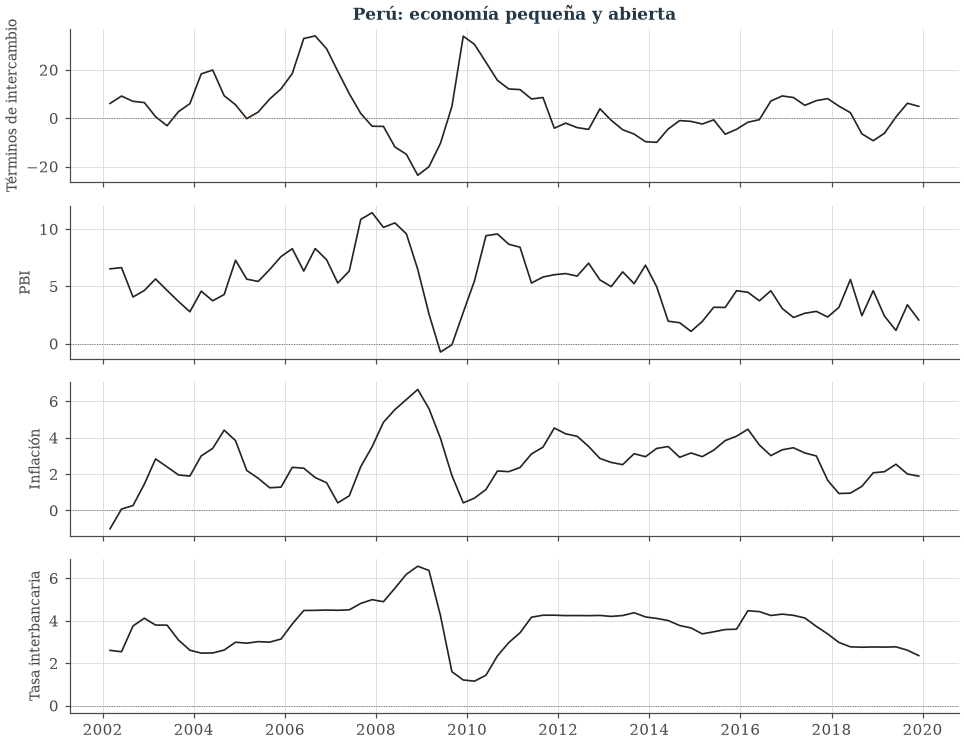

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for ax, col in zip(axes, Y.columns):
    ax.plot(Y.index, Y[col], color="#2A231D", lw=1.1)
    ax.set_ylabel(cd.LABELS[col], fontsize=9)
    ax.axhline(0, color="#6B5F52", lw=0.6, ls=":")
axes[0].set_title("Perú: economía pequeña y abierta", fontsize=11)
fig.tight_layout()
plt.show()

## 1. Por qué la forma reducida no alcanza

Estimamos el VAR bayesiano exactamente como en la sesión 2: prior de Minnesota y muestreador de
Gibbs. Lo nuevo empieza después.

Con dos rezagos hay $k = np + 1 = 9$ coeficientes por ecuación y solo 68 observaciones
efectivas. Por mínimos cuadrados esto sería temerario; el prior es justamente lo que lo hace
viable.

In [ ]:
`BayesianVAR` is imported from `MacroPy`; this cell only instantiates it. Since the notebook already has a `BayesianVAR` instance, Python has allowed the class to be instantiated, so it has no unimplemented abstract methods. To implement methods, provide the `BayesianVAR` class definition.
model.sample_posterior()
model.names = [cd.LABELS[c] for c in Y.columns]     # etiquetas legibles en los gráficos

Sigma = np.median(np.array(model.Sigma_draws), axis=0)
corr = Sigma / np.sqrt(np.outer(np.diag(Sigma), np.diag(Sigma)))
print(f"{len(model.beta_draws)} extracciones de la posterior; {model.ncoeff_eq} coeficientes por ecuación")
pd.DataFrame(corr.round(2), index=Y.columns, columns=Y.columns)

Sampling Posterior: 100%|██████████| 4000/4000 [00:01<00:00, 3223.16it/s]

2000 extracciones de la posterior; 9 coeficientes por ecuación


,tot,y,pi,i
tot,1.00,0.01,-0.28,-0.04
y,0.01,1.00,0.28,0.10
pi,-0.28,0.28,1.00,0.29
i,-0.04,0.10,0.29,1.00


Las innovaciones $\mathbf{u}_t$ están correlacionadas entre sí, y por eso no son experimentos. La
correlación entre la sorpresa de inflación y la sorpresa de tasa es positiva: cuando la inflación
sorprende al alza, la tasa sorprende al alza. Eso es lo que hace un banco central que reacciona, y
es exactamente la razón por la que esa correlación **no** se puede leer como el efecto de la tasa
sobre la inflación.

El supuesto estructural es que esas sorpresas son combinaciones lineales de choques ortogonales:

$$\mathbf{u}_t = S\varepsilon_t, \qquad \mathbb{E}[\varepsilon_t\varepsilon_t'] = I_n
\qquad\Longrightarrow\qquad \Sigma = SS'.$$

Y ahí está el problema: $\Sigma$ es simétrica y aporta $n(n+1)/2$ ecuaciones, mientras que $S$
tiene $n^2$ incógnitas.

In [ ]:
ecuaciones = n * (n + 1) // 2
incognitas = n ** 2
print(f"n = {n}:  ecuaciones = {ecuaciones},  incógnitas = {incognitas},"
      f"  restricciones necesarias = {incognitas - ecuaciones}")

# Cualquier rotacion ortonormal de S reproduce la misma Sigma: mismo ajuste, otra economia.
rng = np.random.default_rng(0)
L = np.linalg.cholesky(Sigma)
Q, R = np.linalg.qr(rng.standard_normal((n, n)))
Q = Q * np.sign(np.diag(R))
S_tilde = L @ Q
print("¿(LQ)(LQ)' = Sigma?", np.allclose(S_tilde @ S_tilde.T, Sigma))
print("impacto de Cholesky, fila de la tasa:", L[3].round(3))
print("impacto rotado,      fila de la tasa:", S_tilde[3].round(3))

Las dos matrices ajustan los datos **idénticamente bien**: tienen la misma verosimilitud. Ninguna
prueba estadística puede escoger entre ellas. La información que falta es económica y hay que
declararla.

## 2. Identificación recursiva: ceros contemporáneos

El esquema más usado ordena las variables de la más lenta a la más rápida en reaccionar dentro del
trimestre y supone que ninguna responde contemporáneamente a los choques de las que vienen después.
Con el orden $(tot, y, \pi, i)$ la matriz de impacto es triangular inferior:

$$
\begin{bmatrix} u_{tot,t} \\ u_{y,t} \\ u_{\pi,t} \\ u_{i,t}\end{bmatrix}
=
\begin{bmatrix}
 s_{11} & 0 & 0 & 0\\
 s_{21} & s_{22} & 0 & 0\\
 s_{31} & s_{32} & s_{33} & 0\\
 s_{41} & s_{42} & s_{43} & s_{44}
\end{bmatrix}
\begin{bmatrix}\varepsilon_{1,t}\\ \varepsilon_{2,t}\\ \varepsilon_{3,t}\\ \varepsilon^{\,pol}_{4,t}\end{bmatrix}
$$

Los seis ceros son exactamente las $n(n-1)/2 = 6$ restricciones que faltaban, y dicen dos cosas.
Hacia abajo: la tasa responde dentro del trimestre a los términos de intercambio, al PBI y a la
inflación. Hacia arriba: el choque de política no mueve ninguna de las tres dentro del mismo
trimestre.

In [ ]:
# A mano, sobre una extraccion cualquiera de la posterior.
d = 0
B_d = model.reshape_beta(model.beta_draws[d], model.ncoeff_eq, n)
S_d = np.linalg.cholesky(model.Sigma_draws[d])

shocks = ["Externo", "Actividad", "Precios", "Política"]
print("¿S S' = Sigma en esta extracción?",
      np.allclose(S_d @ S_d.T, model.Sigma_draws[d]))
pd.DataFrame(S_d.round(3), index=[cd.LABELS[c] for c in Y.columns], columns=shocks)

La cuarta columna es el choque de política: sube la tasa en el trimestre del choque y, por
construcción, no toca a las otras tres en ese momento. El elemento $s_{43}$ es el que da contenido
al orden: ante un choque de precios, la tasa se mueve dentro del mismo trimestre.

Los tres primeros choques llevan el nombre de la variable que encabezan, no el de una
interpretación económica. Llamarlos choque de oferta o de demanda exigiría un argumento que este
esquema no aporta; ese argumento es el tema del notebook B.

### El orden es una restricción económica, no una convención

Cambiar el orden cambia los choques. La práctica mínima es reportar el orden, justificarlo y
mostrar qué pasa con otro razonable.

In [ ]:
# Orden invertido: la tasa primero, los terminos de intercambio al final.
orden_alt = ["i", "pi", "y", "tot"]
model_alt = BayesianVAR(Y[orden_alt], lags=p, prior_type=1, post_draws=4000,
                        burnin=0.5, hor=21, seed=1, progress=False)
model_alt.sample_posterior()

S_alt = np.linalg.cholesky(np.median(np.array(model_alt.Sigma_draws), axis=0))
print("Impacto del choque de política sobre la inflación, en el trimestre del choque")
print(f"  orden (tot, y, pi, i): {L[2, 3]: .3f}   (cero por construcción)")
print(f"  orden (i, pi, y, tot): {S_alt[1, 0]: .3f}   (libre: la inflación sí reacciona)")

## 3. Impulso-respuesta: ¿qué pasaría si?

Identificada la matriz de impacto, el resto es aritmética de la forma companion que ya
construimos en la sesión 1:

$$\Theta_h = \frac{\partial \mathbf{y}_{t+h}}{\partial \varepsilon_t'} = \Psi_h S,
\qquad \Psi_h = J F^h J'.$$

El elemento $(i,k)$ de $\Theta_h$ es la respuesta de la variable $i$ al choque $k$ en el horizonte
$h$, manteniendo los demás choques en cero.

In [ ]:
def wold_weights(model, B, h):
    '''Psi_j = J F^j J' para j = 0, ..., h.'''
    F = model.build_companion_matrix(B, n, p)
    J = np.zeros((n, n * p)); J[:, :n] = np.eye(n)
    out = np.zeros((h + 1, n, n))
    power = np.eye(n * p)
    for j in range(h + 1):
        out[j] = J @ power @ J.T
        power = power @ F
    return out

H = 20
theta_hand = wold_weights(model, B_d, H) @ S_d          # Theta_j = Psi_j S

irf = model.compute_irfs()                              # (draws, hor, vars, shocks)
print("forma de las IRF de MacroPy:", irf.shape)
print("¿coincide la extracción d con el cálculo a mano?",
      np.allclose(theta_hand, irf[d], atol=1e-10))
pd.DataFrame(theta_hand[:5, :, 3].round(3),
             columns=[cd.LABELS[c] for c in Y.columns],
             index=[f"h={j}" for j in range(5)])

In [ ]:
figs = model.compute_irfs(plot_irfs=True, cred_interval=[0.68, 0.95])
plt.show()

La última figura es el choque de política y reproduce los hechos estilizados de la literatura: la
tasa sube, el PBI cae con forma de joroba y toca el mínimo alrededor del cuarto trimestre, y el
efecto se agota hacia el tercer año.

La inflación es el punto incómodo: no baja de inmediato, incluso sube unas centésimas durante el
primer año. Es el ***price puzzle***, y aparece a pesar de haber identificado. La lectura estándar
es que el banco central reacciona a información sobre precios futuros que el sistema no contiene,
de modo que parte de lo que el esquema llama choque de política es en realidad respuesta a una
presión inflacionaria que el VAR no ve.

Guardemos el dato, porque es el que motiva el notebook B: si uno **cree** que un choque
contractivo baja la inflación, puede imponerlo en vez de esperar que salga.

In [ ]:
med = np.median(irf, axis=0)
lo, hi = np.quantile(irf, 0.16, axis=0), np.quantile(irf, 0.84, axis=0)
print("Choque de política monetaria (mediana y banda del 68 %)")
for h in (0, 2, 4, 8, 12):
    print(f"  h={h:2d}  tasa {med[h,3,3]: .3f}   PBI {med[h,1,3]: .3f} "
          f"[{lo[h,1,3]: .3f}, {hi[h,1,3]: .3f}]   inflación {med[h,2,3]: .3f}")
print("\n%% de extracciones con PBI < 0 en h=4:", round(100 * (irf[:, 4, 1, 3] < 0).mean()))

## 4. Descomposición de varianza: ¿cuánto importa?

La impulso-respuesta dice cómo se mueve el sistema ante un choque. La descomposición de varianza
dice cuánto pesa ese choque en promedio. El error de pronóstico a $h$ períodos es
$\sum_{j=0}^{h}\Theta_j\varepsilon_{t+h-j}$ y, como los choques son ortogonales y de varianza
unitaria, su varianza se parte sin residuo:

$$\operatorname{FEVD}_{i,k}(h) = \frac{\sum_{j=0}^{h}\theta_{ik,j}^2}
{\sum_{m=1}^{n}\sum_{j=0}^{h}\theta_{im,j}^2}, \qquad \sum_{k=1}^{n}\operatorname{FEVD}_{i,k}(h)=1.$$

Nótese el parentesco con el ECM de la sesión 1: es el mismo error de pronóstico acumulado, ahora
repartido entre choques en vez de resumido en una banda.

In [ ]:
# A mano, sobre la misma extraccion.
contrib = np.cumsum(theta_hand ** 2, axis=0)            # (h, variable, choque)
shares_hand = contrib / contrib.sum(axis=2, keepdims=True)

fevd = model.compute_fevd()["fevd"]                     # (h, choque, variable), en %
print("forma de la FEVD de MacroPy:", fevd.shape, "  (horizonte, choque, variable)")
print("las columnas suman 100:", np.allclose(fevd.sum(axis=1), 100))

tabla = pd.DataFrame(fevd[7].round(1), index=shocks,
                     columns=[cd.LABELS[c] for c in Y.columns])
print("\nFEVD a 8 trimestres, en %% de la varianza de cada variable")
tabla

In [ ]:
figs = model.compute_fevd(plot_fevd=True,
                          series_titles=[cd.LABELS[c] for c in Y.columns],
                          shock_titles=shocks,
                          title="Descomposición de la varianza del error de pronóstico")
plt.show()

Dos lecturas que conviene fijar.

El choque externo explica una parte grande de la varianza del PBI a dos años: es lo que se espera
de una economía pequeña y abierta, y es el argumento que justifica tratar a los términos de
intercambio como un bloque exógeno.

El choque de política explica **muy poco** del PBI y de la inflación, y bastante de la tasa misma.
Es un resultado repetido en la literatura y se malinterpreta con frecuencia. No dice que la
política monetaria sea irrelevante: dice que casi todo lo que hace el banco central es
sistemático, respuesta a lo que observa, y lo sistemático no es un choque.

## 5. Descomposición histórica: ¿qué pasó?

La descomposición de varianza es un promedio sobre toda la muestra. La descomposición histórica
baja al trimestre concreto: qué choques explican que el PBI de 2009 haya estado donde estuvo.

$$\mathbf{y}_t = \underbrace{\text{base}_t}_{\text{media e inicio}}
+ \sum_{k=1}^{n}\underbrace{\sum_{j=0}^{t-1}\theta_{\cdot k,j}\,\varepsilon_{k,t-j}}_{\text{aporte del choque }k},
\qquad \hat\varepsilon_t = S^{-1}\hat{\mathbf{u}}_t.$$

In [ ]:
hd = model.compute_hd()
print("claves:", list(hd))
print("aportes:", hd["shock"].shape, " (trimestre, choque, variable)")

# La identidad contable es la prueba de que la descomposicion esta bien hecha.
err = np.abs(hd["baseline"] + hd["shock"].sum(axis=1) - model.yy).max()
print(f"¿base + suma de aportes = dato observado?  error máximo {err:.2e}")

In [ ]:
figs = model.compute_hd(plot_hd=True,
                        series_titles=[cd.LABELS[c] for c in Y.columns],
                        shock_titles=shocks,
                        title="Descomposición histórica")
plt.show()

In [ ]:
fechas = pd.DatetimeIndex(hd["dates"])
crisis = (fechas >= "2008-09-01") & (fechas <= "2009-12-01")
aporte = pd.Series(hd["shock"][crisis, :, 1].mean(axis=0), index=shocks)

print("Crisis financiera global, promedio 2008Q3 a 2009Q4")
print(f"  crecimiento observado del PBI      {model.yy[crisis, 1].mean(): .2f} pp")
print(f"  base del modelo                    {hd['baseline'][crisis, 1].mean(): .2f} pp")
print("  aporte de cada choque (pp):")
print(aporte.round(2).to_string())

Las tres lecturas responden preguntas distintas sobre el mismo objeto, y las tres se calculan con
las mismas matrices $\Theta_j$:

| | Pregunta | Objeto |
|:-|:-|:-|
| Impulso-respuesta | ¿qué pasaría si? | un experimento |
| Descomposición de varianza | ¿cuánto importa en general? | un promedio |
| Descomposición histórica | ¿qué pasó en este trimestre? | un relato |

## 6. Exogeneidad de bloque: más ceros, y más creíbles

La identificación recursiva pone ceros en el **impacto**. Para una economía pequeña y abierta hay
un supuesto más fuerte y más defendible: los términos de intercambio no responden a lo que pasa en
Perú, ni contemporáneamente ni con rezago. Eso son ceros en los **coeficientes**, no en $S$.

En `MacroPy` se declara con la máscara `b_exo`.

In [ ]:
b_exo = np.zeros((n, n))
b_exo[0, 1:] = 1        # la ecuacion de tot excluye los rezagos de y, pi, i

model_exo = BayesianVAR(Y, lags=p, prior_type=1, post_draws=4000, burnin=0.5,
                        hor=21, seed=1, b_exo=b_exo, progress=False)
model_exo.sample_posterior()
model_exo.names = [cd.LABELS[c] for c in Y.columns]

fevd_exo = model_exo.compute_fevd()["fevd"]
comparacion = pd.DataFrame(
    {"sin bloque exógeno": fevd[7, :, 0].round(1),
     "con bloque exógeno": fevd_exo[7, :, 0].round(1)}, index=shocks)
print("FEVD de los términos de intercambio a 8 trimestres (%)")
comparacion

Sin la restricción, los choques domésticos explican una parte no trivial de la varianza de los
términos de intercambio a dos años. Es ruido de estimación: el precio mundial del cobre no depende
de la tasa interbancaria peruana. Con `b_exo` esa fuga desaparece por construcción, y los
escenarios externos de la sesión 2 pasan a ser creíbles.

## Ejercicios

1. **Reordene el sistema** poniendo la inflación antes del PBI. ¿Cambia la respuesta del PBI al
   choque de política? ¿Cambia la FEVD? Reporte ambas y decida si el resultado es robusto.

2. **Calcule la FEVD a mano** con `shares_hand` y compárela con la de `MacroPy` en el horizonte 8.
   Cuidado con la orientación de los arreglos: uno es (variable, choque) y el otro, (choque,
   variable).

3. **Recupere los choques estructurales** $\hat\varepsilon_t = S^{-1}\hat{\mathbf{u}}_t$ de una
   extracción y grafique la serie del choque de política. ¿Qué trimestres salen como los más
   contractivos? ¿Coinciden con lo que recuerda de la política monetaria peruana?

4. **Repita la descomposición histórica** de la inflación en lugar del PBI para 2008 y 2022, y
   describa en dos líneas qué choque domina en cada episodio.

5. **Con `b_exo`**, compare la respuesta del PBI al choque externo con y sin exogeneidad de bloque.
   ¿En qué horizonte se separan más y por qué?